# Laser-Driven FMR of Py Probed by XUV T-MOKE

Here, a laser-driven ferromagnetic resonance (FMR) experiment of a permalloy (Py, Ni$_{80}$Fe$_{20}$) film is drafted, which is probed by the transversal magneto-optical Kerr effect (T-MOKE) at the Fe $M_{2,3}$ edges in the extreme ultraviolet (XUV).

The geometry is the following:

* The scattering plane is horizontal.
* The Py film is magnetized in-plane and horizontally, i.e. in the scattering plane along the projection of the beam.
* The external field $B_\mathrm{ext}$ is applied in the scattering plane at an angle $\xi = 30°$ from the film surface.
* The probe is $\pi$-polarized, so that the T-MOKE picks up the in-plane magnetization perpendicular to the scattering plane, i.e. the vertical component.

The pump pulse demagnetizes the Py within a picosecond.
This reduces the shape anisotropy, so that the equilibrium of the magnetization tilts towards the field and the magnetization starts to precess around its new equilibrium, as first shown by van Kampen et al., PRL 88, 227201 (2002).
The equilibrium magnetization and the field both lie in the scattering plane, so that the vertical component is zero before the excitation and is a pure precession signal afterwards.

In the coordinate system of **udkm1Dsim**, the film normal is along $z$ and the scattering plane is the $yz$-plane.
Hence, the initial magnetization is along $y$, the field is $\mathbf{B}_\mathrm{ext} = B_\mathrm{ext}(0, \cos\xi, \sin\xi)$, and the T-MOKE probes $m_x$.

The excitation by a two-temperature model (2TM), the Landau-Lifshitz-Gilbert (LLG) equation, and the resonant magnetic XUV reflectivity by the `Elzo` formalism follow the [LLG example](https://udkm1dsim.readthedocs.io/en/latest/examples/04-magnetization/01-LLG.html) and the [XUV polarimetry example](https://udkm1dsim.readthedocs.io/en/latest/examples/07-xray_reflectivity/02-XUV_polarimetry.html) of **udkm1Dsim**.
All material parameters are typical values of Py and are not taken from a specific work.

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import udkm1Dsim as ud
from udkm1Dsim.simulations.solvers import mean_field

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

try:
    plt.style.use(["mbistyles.base", "mbistyles.paper"])  # matplotlib styles of the MBI
except OSError:
    pass  # mbistyles is not installed, the default matplotlib style is used

/home/schick/Programming/git/laser-fmr-xuv/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Structure

The sample is a 20 nm thick Py film with a 2 nm thick Ta cap on a Si substrate.

For the magnetic Fe atom, the measured charge and magnetic form factors at the Fe $M_{2,3}$ edges of Willems et al., PRL 122, 217202 (2019) are used.
All other atoms use the atomic form factors of Henke et al.

:::{attention}
**udkm1Dsim** has no magnetic form factors at the Ni $M_{2,3}$ edges so far, so that the Ni in Py is non-magnetic here and only the Fe contributes to the T-MOKE.
:::

In [2]:
Fe = ud.Atom("Fe", atomic_form_factor_path="./Fe_XUV.cf", magnetic_form_factor_path="./Fe_XUV.mf")
Ni = ud.Atom("Ni", atomic_form_factor_source="henke")
Ta = ud.Atom("Ta", atomic_form_factor_source="henke")
Si = ud.Atom("Si", atomic_form_factor_source="henke")

Py = ud.AtomMixed("Py")
Py.add_atom(Ni, 0.8)
Py.add_atom(Fe, 0.2)

The Py has a saturation magnetization of $M_s = 8.0\times10^5$ A/m at room temperature, i.e. a demagnetizing field of $\mu_0 M_s = 1.0$ T, and a Curie temperature of $T_\mathrm{C} = 850$ K.
As in the LLG example, $M_s$ is scaled to 0 K with the mean-field magnetization of 300 K, and the atomic magnetic moment follows from the number density of the atoms.
Py has a negligible crystalline anisotropy, so that only the shape anisotropy $K_z = -\mu_0 M_s^2/2$ is taken into account.
Its magnetostriction is close to zero as well, so that the magnetoelastic coupling and hence the strain are neglected.
The gyromagnetic ratio $\gamma/2\pi = -29.5$ GHz/T corresponds to $g = 2.1$ and the Gilbert damping is $\alpha = 0.01$.

The 2TM uses simple mass-specific heat capacities and an electron-phonon coupling of $4\times10^{17}$ W/(m³ K).
The pump at 800 nm is absorbed according to the refractive index of the layers, which is given as `fallback` outside of the energy range of the atomic form factors.
The Py is discretized into 2 nm thick layers.

In [3]:
rho = 8720 * u.kg / u.m**3  # density
T_C = 850 * u.K  # Curie temperature
spin = 0.5  # effective spin S
# saturation magnetization at room temperature and its mean-field scaling to 0 K
M_s_300 = 8.0e5 * u.A / u.m
m_300 = mean_field.mean_field_magnetization((300 * u.K / T_C).m_as(""), spin)
M_s = M_s_300 / m_300
K_shape = (u.mu_0 * M_s**2 / 2).to("J/m**3")  # shape anisotropy
# atomic magnetic moment from the number density of the atoms
n_Py = (rho / (58.1 * u.g / u.mol) * u.N_A).to("1/m**3")
mu = (M_s / n_Py).to("bohr_magneton")

layer_Py = ud.AmorphousLayer(
    "Py",
    "Permalloy",
    atom=Py,
    structural=ud.StructuralParameters(thickness=2 * u.nm, density=rho),
    thermal=ud.ThermalParameters(
        heat_capacity=["0.12*T", 450 * u.J / (u.kg * u.K)],
        therm_cond=["25*T_0/T_1", 5 * u.W / (u.m * u.K)],
        sub_system_coupling=["-4e17*(T_0-T_1)", "4e17*(T_0-T_1)"],
        sub_system_labels=["e", "p"],
    ),
    magnetic=ud.MagneticParameters(
        mag_saturation=M_s,
        gilbert_damping=0.01,
        gyromagnetic_ratio=-2 * np.pi * 29.5e9 * u.rad / u.s / u.T,
        anisotropy=[0, 0, -1] * K_shape,  # hard axis along z
        aniso_exponent=2,
        exch_stiffness=1.3e-11 * u.J / u.m,
        eff_spin=spin,
        curie_temp=T_C,
        mag_moment=mu,
        magnetization=(0, 1, 0),  # in-plane and horizontal
    ),
)
layer_Py.set_dielectric_from_atoms(fallback=ud.Dispersion.from_ref_index(2.2 + 4.2j))

print(f"mean-field magnetization at 300 K: {m_300:.3f}")
print(f"atomic magnetic moment: {mu:.3f~P}")
layer_Py.magnetic

mean-field magnetization at 300 K: 0.993
atomic magnetic moment: 0.961 µ_B


Parameter,Symbol,Value,Unit
eff_spin,S,0.5,
curie_temp,TC,850,K
mf_exch_coupling,J,1.174×10−20,kg m2/s2
lamda,λ,0,
mag_moment,μ,8.915×10−24,A m2
aniso_exponent,β,2,
anisotropy,K,"[0, 0, −4.08×105]",J/m3
exch_stiffness,Aex,"[1.3×10−11, 1.3×10−11, 1.3×10−11]",J/m
mag_saturation,Ms,8.058×105,J/(m3 T)
magnetization,x,0,


In [4]:
layer_Ta = ud.AmorphousLayer(
    "Ta",
    "Tantalum",
    atom=Ta,
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=16650 * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=["0.023*T", 140 * u.J / (u.kg * u.K)],
        therm_cond=["52*T_0/T_1", 5 * u.W / (u.m * u.K)],
        sub_system_coupling=["-1e17*(T_0-T_1)", "1e17*(T_0-T_1)"],
        sub_system_labels=["e", "p"],
    ),
)
layer_Ta.set_dielectric_from_atoms(fallback=ud.Dispersion.from_ref_index(1.1 + 3.3j))

# the Si has no electronic heat conductivity
layer_Si = ud.AmorphousLayer(
    "Si",
    "Silicon",
    atom=Si,
    structural=ud.StructuralParameters(thickness=10 * u.nm, density=2330 * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=[1 * u.J / (u.kg * u.K), 700 * u.J / (u.kg * u.K)],
        therm_cond=[0, 150 * u.W / (u.m * u.K)],
        sub_system_coupling=[0, 0],
        sub_system_labels=["e", "p"],
    ),
)
layer_Si.set_dielectric_from_atoms(fallback=ud.Dispersion.from_ref_index(3.69 + 0.0065j))

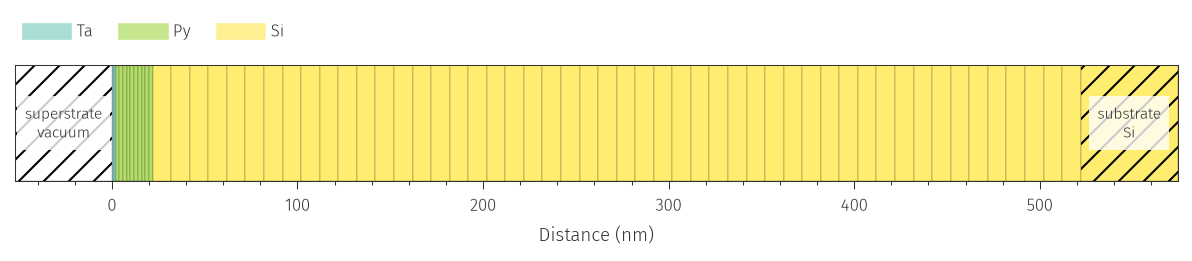

In [5]:
S = ud.Structure("Ta/Py/Si")
S.add_sub_structure(layer_Ta, 2)
S.add_sub_structure(layer_Py, 10)
S.add_sub_structure(layer_Si, 50)
# semi-infinite and static Si substrate
S.add_substrate(layer_Si)

select_Py = S.positions_per_unique_layer["Py"]
S.visualize()

## Static T-MOKE

In order to choose the photon energy and the incidence angle of the probe, the static T-MOKE asymmetry

\begin{align*}
A = \frac{R(+m_x) - R(-m_x)}{R(+m_x) + R(-m_x)}
\end{align*}

of the $\pi$-polarized probe is calculated for a Py film magnetized along $x$.
The reflectivity `R_phi` for the opposite magnetization is returned by `Elzo` together with `R`.

In [6]:
dyn = ud.Elzo(S, True)
dyn.save_data = False
dyn.disp_messages = True
dyn.progress_bar = False
dyn.set_incoming_polarization("pi")
dyn.energy = np.r_[48:62:0.1] * u.eV
dyn.theta = np.r_[20:70:0.5] * u.deg
dyn

incoming polarizations set to: pi


parameter,value
force recalc,True
cache directory,./
display messages,True
save data,False
progress bar,False
energy,48 eV .. 61.9 eV
wavelength,20.03 nm .. 25.83 nm
wavenumber,0.2433 1/nm .. 0.3137 1/nm
theta,20 deg .. 69.5 deg
q_z,0.1664 1/nm .. 0.5877 1/nm


In [7]:
# magnetization of the sub-structures Ta, Py, and Si along x
res_static = dyn.homogeneous_reflectivity_transmissivity(
    magnetizations=np.array([[0, 0, 0], [m_300, 0, 0], [0, 0, 0]])
)
asym_static = (res_static.R - res_static.R_phi) / (res_static.R + res_static.R_phi)

# probe energy and angle at the largest asymmetry
i_E, i_theta = np.unravel_index(np.argmax(np.abs(asym_static)), asym_static.shape)
energy_probe = res_static.quantity("energy", "eV")[i_E]
theta_probe = res_static.quantity("theta", "deg")[i_E, i_theta]
print(f"largest asymmetry {asym_static[i_E, i_theta]:.3f} at {energy_probe:.1f~P} and {theta_probe:.1f~P}")

Calculating _homogeneous_reflectivity_transmissivity_ ...


Elapsed time for _homogeneous_reflectivity_transmissivity_: 0.171033 s


largest asymmetry -0.070 at 54.0 eV and 47.0 deg


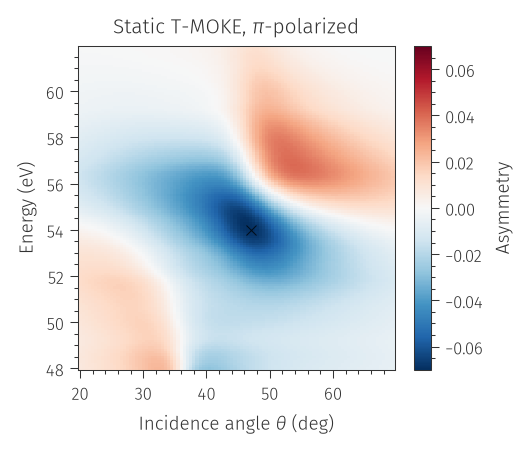

In [8]:
plt.figure(figsize=[3.4, 2.8])
plt.pcolormesh(
    res_static.quantity("theta", "deg")[0, :],
    res_static.quantity("energy", "eV"),
    asym_static,
    shading="auto",
    cmap="RdBu_r",
    vmin=-np.abs(asym_static).max(),
    vmax=np.abs(asym_static).max(),
)
plt.colorbar(label="Asymmetry")
plt.plot(theta_probe, energy_probe, "kx")
plt.xlabel(r"Incidence angle $\theta$ (deg)")
plt.ylabel("Energy (eV)")
plt.title(r"Static T-MOKE, $\pi$-polarized")
plt.show()

The asymmetry is largest close to the Brewster angle of about 45° and just above the Fe $M_3$ edge.
This probe energy and angle are used in the following.

In [9]:
dyn.energy = np.r_[energy_probe.m_as("eV")] * u.eV
dyn.theta = np.r_[theta_probe.m_as("deg")] * u.deg

## Excitation

The Py is excited by a 100 fs pump pulse at 800 nm under normal incidence with an incidence fluence of 5 mJ/cm².

In [10]:
delays = np.r_[-20:1000:0.5] * u.ps

h = ud.Heat(S, True)
h.save_data = False
h.disp_messages = True
h.progress_bar = False
h.heat_diffusion = True
h.boundary_conditions = {"top_type": "isolator", "bottom_type": "isolator"}
h.excitation = {
    "fluence": [5] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [0.1] * u.ps,
    "wavelength": 800 * u.nm,
    "theta": 90 * u.deg,
}
h

parameter,value
force recalc,True
cache directory,./
display messages,True
save data,False
progress bar,False
excitation fluence,5 mJ/cm²
excitation delay,0 ps
excitation pulse length,0.1 ps
excitation wavelength,800 nm
excitation theta,90 deg


In [11]:
res_temp = h.get_temp_map(delays, 300 * u.K)

Surface incidence fluence scaled by factor 1.0000 due to incidence angle theta=90.00 deg
Absorption of pulse 0 at 0 ps by Parratt for 800 nm, theta = 90 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 61.0 %, absorption in the sample of 21.2 %, and transmission into the substrate of 17.9 %.
Calculating _heat_diffusion_ for pulse 0 of 1 ...
Elapsed time for _heat_diffusion_ with 1 excitation(s): 0.063025 s
Calculating _heat_diffusion_ without excitation...
Elapsed time for _heat_diffusion_: 0.026970 s
Elapsed time for _temp_map_: 0.123418 s


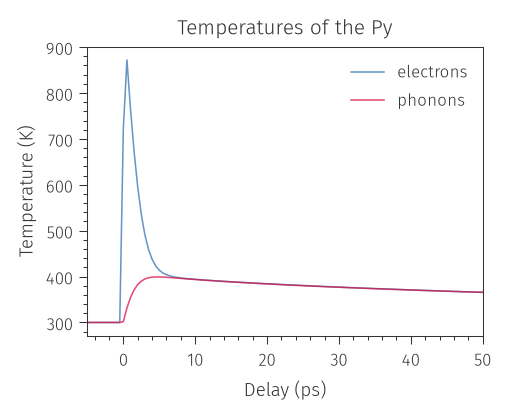

In [12]:
plt.figure()
plt.plot(res_temp.quantity("delays", "ps"), np.mean(res_temp.temp_map[:, select_Py, 0], axis=1), label="electrons")
plt.plot(res_temp.quantity("delays", "ps"), np.mean(res_temp.temp_map[:, select_Py, 1], axis=1), label="phonons")
plt.xlim(-5, 50)
plt.xlabel("Delay (ps)")
plt.ylabel("Temperature (K)")
plt.legend()
plt.title("Temperatures of the Py")
plt.show()

## Magnetization Dynamics

The magnetization amplitude of the LLG follows the mean-field magnetization of the phonon temperature, i.e. the adiabatic limit of the LLG example.
The magnetization starts in its equilibrium of the external field of 100 mT at $\xi = 30°$ from the film surface.

In [13]:
B_0 = 100 * u.mT  # strength of the external field
xi = 30 * u.deg  # angle of the field from the film surface
B_ext = B_0 * np.array([0, np.cos(xi), np.sin(xi)])
init_mag = m_300 * np.array([0, 1, 0])

llg = ud.LLG(S, True)
llg.save_data = False
llg.disp_messages = True
llg.progress_bar = False
llg.ode_options["method"] = "RK23"
llg.temp_sub_system = 1  # the phonons
llg

Landau-Lifshitz-Gilbert Magnetization Dynamics simulation properties:

========================  =======
               parameter  value
========================  =======
            force recalc  True
         cache directory  ./
        display messages  True
               save data  False
            progress bar  False
  temperature sub-system  1
magnetization sub-system
========================  =======

This is the current structure for the simulations:

Structure properties:

Name   : Ta/Py/Si
Thickness : 522 nm
----
2 times Tantalum: 2 nm
10 times Permalloy: 20 nm
50 times Silicon: 500 nm
----
Superstrate (semi-infinite):
----
1 times vacuum: 1 nm
----
Substrate (semi-infinite):
----
1 times Silicon: 10 nm

In [14]:
res_mag = llg.get_magnetization_map(
    delays, temp_map=res_temp, init_magnetization=init_mag, B_ext=B_ext, equilibrate=True
)
m_xyz = np.mean(res_mag.magnetization_map[:, select_Py, :], axis=1)
elevation = np.degrees(np.arctan2(m_xyz[0, 2], m_xyz[0, 1]))
print(f"equilibrium magnetization {elevation:.1f}° out of the film plane")

Calculating _magnetization_map_ ...
Calculating _mf_magnetization_map_ ...
Elapsed time for _mf_magnetization_map_: 0.077944 s


Elapsed time for _LLG_: 1.180828 s
Elapsed time for _magnetization_map_: 1.204820 s
equilibrium magnetization 2.6° out of the film plane


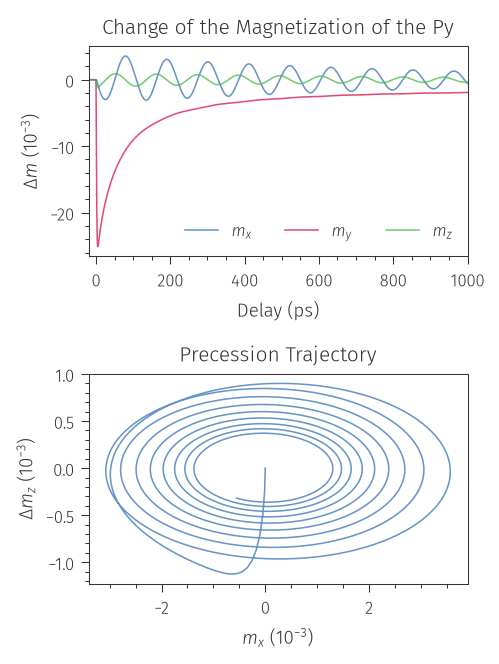

In [15]:
plt.figure(figsize=[3.4, 4.5])
plt.subplot(2, 1, 1)
for k, label in enumerate(["$m_x$", "$m_y$", "$m_z$"]):
    plt.plot(res_mag.quantity("delays", "ps"), 1e3 * (m_xyz[:, k] - m_xyz[0, k]), label=label)
plt.xlim(-20, 1000)
plt.xlabel("Delay (ps)")
plt.ylabel(r"$\Delta m$ ($10^{-3}$)")
plt.legend(ncol=3)
plt.title("Change of the Magnetization of the Py")

plt.subplot(2, 1, 2)
plt.plot(1e3 * m_xyz[:, 0], 1e3 * (m_xyz[:, 2] - m_xyz[0, 2]))
plt.xlabel(r"$m_x$ ($10^{-3}$)")
plt.ylabel(r"$\Delta m_z$ ($10^{-3}$)")
plt.title("Precession Trajectory")

plt.tight_layout()
plt.show()

The drop of the amplitude by the demagnetization shows up in $m_y$, while $m_x$ and $m_z$ precess around the new, slightly tilted equilibrium.
The vertical component $m_x$ oscillates around zero.

The frequency of small precessions follows from the Smit-Beljers formula as in the LLG example, with the polar angle $\theta$ of the magnetization from the film normal and the field at $90° - \xi$ from the film normal.
The demagnetizing field $\mu_0 M_s m$ is taken at the mean-field magnetization of the Py at the late delays.

In [16]:
# here gamma is the gyromagnetic ratio and not the azimuthal angle of the magnetization_map
gamma = abs(layer_Py.gyromagnetic_ratio.to("rad/(s*T)").magnitude)
alpha = layer_Py.gilbert_damping.magnitude
late = res_mag.quantity("delays", "ps").magnitude > 500
m_late = np.mean(np.linalg.norm(m_xyz[late, :], axis=1))
B_d = (u.mu_0 * M_s).m_as("T") * m_late  # demagnetizing field
B = B_0.m_as("T")
xi_B = np.pi / 2 - xi.m_as("rad")  # field angle from the film normal

theta = np.linspace(0, np.pi, 100001)
F = -B * (np.sin(xi_B) * np.sin(theta) + np.cos(xi_B) * np.cos(theta)) + B_d / 2 * np.cos(theta) ** 2
theta_0 = theta[np.argmin(F)]
F_tt = B * np.cos(theta_0 - xi_B) - B_d * np.cos(2 * theta_0)
F_pp = B * np.sin(xi_B) * np.sin(theta_0)
f_smit_beljers = gamma / (2 * np.pi * (1 + alpha**2)) * np.sqrt(F_tt * F_pp) / np.sin(theta_0)
print(f"Smit-Beljers frequency: {f_smit_beljers * 1e-9:.2f} GHz")

# spectrum of the simulated precession after the excitation
t = res_mag.quantity("delays", "s").magnitude
after = t >= 0
freqs = np.fft.rfftfreq(8 * np.sum(after), t[1] - t[0])
spectrum = np.abs(np.fft.rfft(m_xyz[after, 0] * np.hanning(np.sum(after)), 8 * np.sum(after)))
print(f"simulated frequency: {freqs[np.argmax(spectrum)] * 1e-9:.2f} GHz")

Smit-Beljers frequency: 9.06 GHz
simulated frequency: 9.00 GHz


## Transient T-MOKE

The `magnetization_map` is handed to the `Elzo` simulation, which calculates the reflectivity for all delays.
The asymmetry with the reflectivity `R_phi` of the opposite magnetization is linear in $m_x$, since the contributions of $m_y$ (L-MOKE) and $m_z$ (P-MOKE) to the reflectivity of the $\pi$-polarized probe without analyzer are of second order.

In [17]:
res_R = dyn.inhomogeneous_reflectivity_transmissivity(magnetization_map=res_mag)
R, R_phi = res_R.R[:, 0, 0], res_R.R_phi[:, 0, 0]
asym = (R - R_phi) / (R + R_phi)

Calculating _inhomogeneous_reflectivity_transmissivity_Elzo_ ...


Elapsed time for _inhomogeneous_reflectivity_transmissivity_Elzo_: 26.093450 s


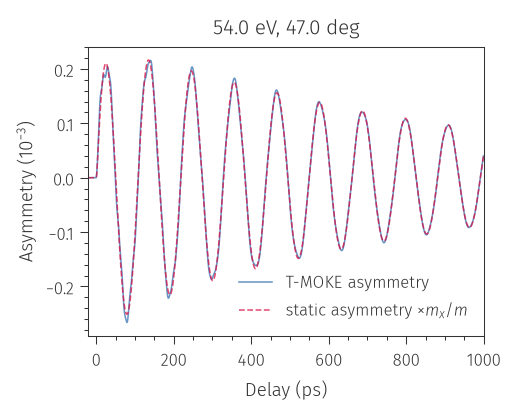

In [18]:
plt.figure()
plt.plot(res_R.quantity("delays", "ps"), 1e3 * asym, label="T-MOKE asymmetry")
plt.plot(
    res_mag.quantity("delays", "ps"),
    1e3 * asym_static[i_E, i_theta] * m_xyz[:, 0] / m_300,
    "--",
    label=r"static asymmetry $\times m_x/m$",
)
plt.xlim(-20, 1000)
plt.xlabel("Delay (ps)")
plt.ylabel(r"Asymmetry ($10^{-3}$)")
plt.legend()
plt.title(f"{energy_probe:.1f~P}, {theta_probe:.1f~P}")
plt.show()

The transient asymmetry follows the vertical magnetization $m_x$ scaled by the static asymmetry and shows the precession free of a background of the demagnetization.

## Reversal of the Field

The asymmetry above requires the reversal of $m_x$ alone, which is not accessible in the experiment.
Reversing the external field $\mathbf{B}_\mathrm{ext} \rightarrow -\mathbf{B}_\mathrm{ext}$ corresponds to a rotation of the whole experiment by 180° around the $x$-axis, which leaves the shape anisotropy unchanged.
The LLG is invariant under rotations, so that the magnetization after the field reversal is $(m_x, -m_y, -m_z)$, i.e. **the precession signal $m_x$ does not reverse**.
In contrast, the field at $\xi \rightarrow 180° - \xi$, i.e. with the reversed in-plane component only, corresponds to a rotation by 180° around the film normal $z$ and gives $(-m_x, -m_y, m_z)$.

Both are simulated in order to compare the pump-induced change of the reflectivity $\Delta R / R$ at a fixed field.

In [19]:
llg.disp_messages = False
dyn.disp_messages = False
fields = {
    r"$\xi = 30°$": B_ext,
    r"$-\mathbf{B}_\mathrm{ext}$": -B_ext,
    r"$\xi = 150°$": B_0 * np.array([0, np.cos(180 * u.deg - xi), np.sin(180 * u.deg - xi)]),
}
reflectivities = {}
m_x_fields = {}
for label, B_ext_i in fields.items():
    # the initial magnetization along the in-plane component of the field
    init_mag_i = m_300 * np.array([0, np.sign(B_ext_i[1].magnitude), 0])
    res_mag_i = llg.get_magnetization_map(
        delays, temp_map=res_temp, init_magnetization=init_mag_i, B_ext=B_ext_i, equilibrate=True
    )
    m_x_fields[label] = np.mean(res_mag_i.magnetization_map[:, select_Py, 0], axis=1)
    reflectivities[label] = dyn.inhomogeneous_reflectivity_transmissivity(
        magnetization_map=res_mag_i
    ).R[:, 0, 0]

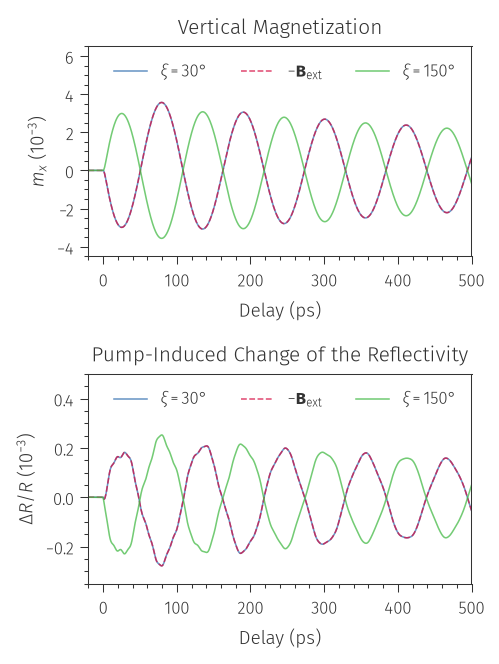

In [20]:
plt.figure(figsize=[3.4, 4.5])
plt.subplot(2, 1, 1)
for label, ls in zip(fields.keys(), ["-", "--", "-"]):
    plt.plot(res_mag.quantity("delays", "ps"), 1e3 * m_x_fields[label], ls, label=label)
plt.xlim(-20, 500)
plt.ylim(-4.5, 6.5)
plt.xlabel("Delay (ps)")
plt.ylabel(r"$m_x$ ($10^{-3}$)")
plt.legend(ncol=3)
plt.title("Vertical Magnetization")

plt.subplot(2, 1, 2)
for (label, R_i), ls in zip(reflectivities.items(), ["-", "--", "-"]):
    plt.plot(res_R.quantity("delays", "ps"), 1e3 * (R_i / R_i[0] - 1), ls, label=label)
plt.xlim(-20, 500)
plt.ylim(-0.35, 0.5)
plt.xlabel("Delay (ps)")
plt.ylabel(r"$\Delta R / R$ ($10^{-3}$)")
plt.legend(ncol=3)
plt.title("Pump-Induced Change of the Reflectivity")

plt.tight_layout()
plt.show()

The reversed field gives the same $m_x$ and the same $\Delta R / R$, so that the usual T-MOKE asymmetry of opposite fields cancels the precession.
The field at $\xi = 150°$ reverses $m_x$ and $\Delta R / R$.
Hence, the precession is measured either as $\Delta R / R$ at a fixed field or by the asymmetry of the fields at $\xi$ and $180° - \xi$, which cancels non-magnetic contributions to $\Delta R / R$, e.g. of the hot electrons and the strain, which are not included here.